In [21]:
%pylab inline

import gc
import os
import pltutil
import catutil
import treecorr
import numpy as np
import astropy.io.ascii as ascii
import astropy.io.fits as pyfits
import astropy.table as astTable
import matplotlib.pylab as plt

def get_rho_all(ccc,debias=False):
    ra,dec=catutil.get_radec(ccc)
    if debias:
        denom=ccc['i_sdssshape_psf_shape11']+ccc['i_sdssshape_psf_shape22']
        nom1=(ccc['i_sdssshape_shape11']-ccc['i_sdssshape_shape22'])/2.
        psf1=(ccc['i_sdssshape_psf_shape11']-ccc['i_sdssshape_psf_shape22'])/2.
        nom1=nom1-psf1
        nom2=(ccc['i_sdssshape_shape12']-ccc['i_sdssshape_psf_shape12'])
        dg1=nom1/denom
        dg2=nom2/denom
    else:
        g1Star,g2Star=catutil.get_sdss_ellip(ccc,return_shear=True)
        g1PSF,g2PSF=catutil.get_psf_ellip(ccc,return_shear=True)
        dg1=   g1Star-g1PSF
        dg2=   g2Star-g2PSF
    return {'ra':ra,'dec':dec,'dg1':dg1,'dg2':dg2}

def plotGG(_ax,_ra,_dec,_g1,_g2,_cc,_g1B=None,_g2B=None,weights=None):
    cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.005,max_sep=0.2,sep_units='degree')
    catT1=   treecorr.Catalog(g1=_g1,g2=-_g2,\
                                ra=_ra,dec=_dec,\
                                ra_units='deg',dec_units='deg',w=weights) 
    if _g1B is None:
        cor.process(catT1,catT1)
    else:
        catTB=   treecorr.Catalog(g1=_g1B,g2=-_g2B,\
                    ra=_ra,dec=_dec,\
                    ra_units='deg',dec_units='deg',w=weights) 
        cor.process(catT1,catTB)

    msk=cor.xip>0
    xrr=cor.rnom.copy()[msk]*60.
    xxp=cor.xip.copy()[msk]
    xxv=np.sqrt(cor.varxi.copy()/2.)[msk]
    _ax.errorbar(xrr,xxp,xxv,fmt='o',\
                color=_cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)
    nnn=np.sum(msk)
    print(nnn)
    if nnn<20:
        xrr=cor.rnom.copy()[~msk]*60.
        xxp=cor.xip.copy()[~msk]
        xxv=np.sqrt(cor.varxi.copy()/2.)[~msk]
        _ax.errorbar(xrr,-xxp,xxv,fmt='s',\
                    color=_cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)

    cor.clear()
    return

Populating the interactive namespace from numpy and matplotlib


In [22]:
datDir='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest/'
datDirR='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest2/'
datDir2='wrkDir/s19/s19-pre/psf_test_from_wentao/results/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'
fc2='#747778'
fc1='#cbd2d6'
req=ascii.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']

In [23]:
if True:
    # determine pend
    pend='fdcut'#-bdcut2'#-bdcut3'
    allname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_star.fits'
    elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_nonpsfstars.fits'
    cat1=pyfits.getdata(allname)
    cat2=pyfits.getdata(elinpname)
    hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    if 'fdcut' in pend:
        maskP1=catutil.get_FDFC_flag(cat1,hpfname=hpfname)
        maskP2=catutil.get_FDFC_flag(cat2,hpfname=hpfname)
        if 'bdcut' in pend:
            cut=eval(pend.split('bdcut')[-1])
            maskP1=maskP1&(np.log10(cat1['i_blendedness_abs'])<-cut)
            maskP2=maskP2&(np.log10(cat2['i_blendedness_abs'])<-cut)
    else:
        maskP1=np.ones(len(cat1),dtype=bool)
        maskP2=np.ones(len(cat2),dtype=bool)

    cat3=cat1[~cat1['i_calib_psf_used']&maskP1]
    cat1=cat1[cat1['i_calib_psf_used']&maskP1]
    cat2=cat2[maskP2]
else:
    pend='s16a'
    dataAll=[]
    for fieldname in catutil.field_names:
        fname='/work/xiangchong.li/work/galSim-HSC/database/s16/S16AStandardV2/field/%s_stars.fits'  %(fieldname)
        data=astTable.Table.read(fname)
        dataAll.append(data)
        del data
        gc.collect()
    cat=astTable.vstack(dataAll)
    cat1=cat[cat['icalib_psf_used']]
    cat2=cat[~cat['icalib_psf_used']]

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


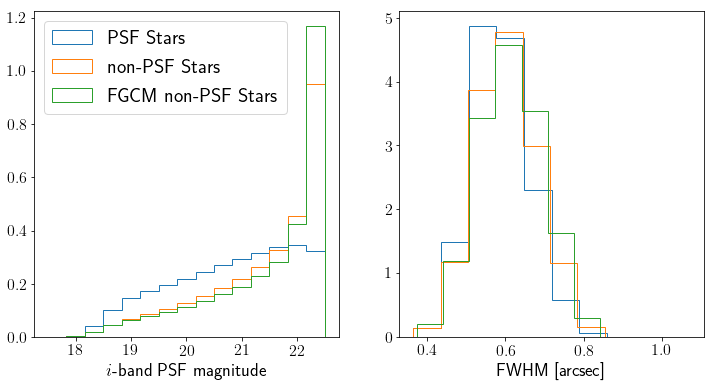

In [24]:
plt.close()
w2=None
fig=plt.figure(figsize=(12,6))
ax=fig.add_subplot(1,2,1)
hist1,bb,_xx=ax.hist(cat1['i_psfflux_mag'],label='PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
ax.hist(cat3['i_psfflux_mag'],label='non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
hist2,bb,_xx=ax.hist(cat2['i_psfflux_mag'],label='FGCM non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step',weights=w2)
ax.legend(loc='upper left')
ax.set_xlabel(r'$i$-band PSF magnitude')
ax=fig.add_subplot(1,2,2)
ax.hist(catutil.get_psf_size(cat1),label='PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat3),label='non-PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat2),label='FGCM non-PSF Stars',density=True,histtype='step')
ax.set_xlabel('FWHM [arcsec]')
w2_tmp=hist1/hist2
w2=w2_tmp[np.digitize(cat2['i_psfflux_mag'],bins=bb)-1]

In [25]:
rhoA=get_rho_all(cat1)
rhoB=get_rho_all(cat1,debias=True)
w2=None

20
20


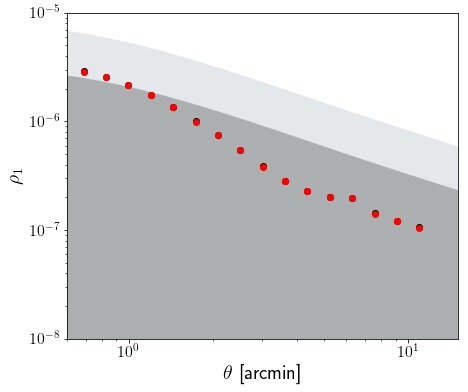

In [27]:
plt.close()

# requirement
rr,rho134,rho25=np.loadtxt(os.path.join(datDir,'rho_requirements.txt'),unpack=True,comments='#')
req=ascii.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']
rr=rr*60
rrn=rrn*60

fig=plt.figure(figsize=(7,6))
fig.set_rasterized(True) 

# rho1
ax=fig.add_subplot(1,1,1)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)
plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['dg1'],rhoA['dg2'],'black',weights=None)
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['dg1'],rhoB['dg2'],'red',weights=w2)
ax.set_xscale('log')
ax.set_xlim(0.01*60,15.)
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_1$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [arcmin]",fontsize=20.0)
ax.set_ylim(1e-8,1e-5)
ax.set_rasterized(True)